## MARBL diagnostics, compare timeseries of global metrics between 2 cases


In [121]:
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
import os
from glob import glob
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cftime
import utils
import pandas as pd
# import pop_tools
import matplotlib.gridspec as gridspec
import matplotlib.colors as colors
from xgcm import Grid
xr.set_options(keep_attrs=True);

### Define cases

In [2]:
case = 'g.e30_a09g.GW1850MARBL_JRA.TL319_t233_wgx3_hycom1_N75.OAEcontrol'
case2 = 'g.e30_a09g.GW1850MARBL_JRA.TL319_t233_wgx3_hycom1_N75.baselineOAE'
user = 'kristenk'

## Define the year range to examine and get the CESM history files

In [3]:
start_yr = 1
num_years = 40
endyr = start_yr + num_years 

#### Now grab the 2-D variables

In [4]:
files = []
for year in range(start_yr,endyr):
    yr4="{:04d}".format(year)
    #print('doing simulation year', year, '!')
    for month in range(1, 13):
    
        mo2="{:02d}".format(month)
        files.extend(sorted(glob(f'/glade/derecho/scratch/{user}/archive/{case}/ocn/hist/{case}.mom6.h.bgc.native.{yr4}-{mo2}.nc')))

In [5]:
ds_ctrl = xr.open_mfdataset(files,decode_times=True,decode_coords=False, combine='nested',concat_dim='time')

In [6]:
files = []
for year in range(start_yr,endyr):
    yr4="{:04d}".format(year)
    #print('doing simulation year', year, '!')
    for month in range(1, 13):
    
        mo2="{:02d}".format(month)
        files.extend(sorted(glob(f'/glade/derecho/scratch/{user}/archive/{case}/ocn/hist/{case}.mom6.h.bgc.z.{yr4}-{mo2}.nc')))

In [7]:
# def preprocess(ds):
#     ds=ds.isel(z_l=0)
#     return ds

In [8]:
ds_ctrl2 = xr.open_mfdataset(files,decode_times=True,decode_coords=False, concat_dim='time',combine='nested') #,preprocess=preprocess)

### get the second case

In [9]:
files = []
for year in range(start_yr,endyr):
    yr4="{:04d}".format(year)
    #print('doing simulation year', year, '!')
    for month in range(1, 13):
    
        mo2="{:02d}".format(month)
        files.extend(sorted(glob(f'/glade/derecho/scratch/{user}/archive/{case2}/ocn/hist/{case2}.mom6.h.bgc.native.{yr4}-{mo2}.nc')))

In [10]:
ds_exp = xr.open_mfdataset(files,decode_times=True,decode_coords=False, combine='nested', concat_dim='time')

In [11]:
files = []
for year in range(start_yr,endyr):
    yr4="{:04d}".format(year)
    #print('doing simulation year', year, '!')
    for month in range(1, 13):
    
        mo2="{:02d}".format(month)
        files.extend(sorted(glob(f'/glade/derecho/scratch/{user}/archive/{case2}/ocn/hist/{case2}.mom6.h.bgc.z.{yr4}-{mo2}.nc')))

In [12]:
ds_exp2 = xr.open_mfdataset(files,decode_times=True,decode_coords=False, combine='nested', concat_dim='time') #,preprocess=preprocess)

### Keep only the variables we need (use this list for both 2-D and 3-D datasets)

In [13]:
variables2d = ['FG_CO2','photoC_cocco_zint','photoC_diat_zint','photoC_TOT_zint',
               'photoC_sp_zint','CaCO3_PROD_zint_100m','POC_FLUX_100m','photoC_diaz_zint','calcToSed','pCO2SURF'] 
variables3d = ['ALK'] 
coords = {'x':'yh','y':'xh'}

### Drop unnecessary variables

In [14]:
keepthese=['z_l','z_i','time_bounds','time'] + variables2d + list(coords.values())
ds_ctrl = ds_ctrl.drop([v for v in ds_ctrl.variables if v not in keepthese])
ds_exp = ds_exp.drop([v for v in ds_exp.variables if v not in keepthese])

In [15]:
keepthese=['z_l','z_i','time_bounds','time'] + variables3d + list(coords.values())
ds_ctrl2 = ds_ctrl2.drop([v for v in ds_ctrl2.variables if v not in keepthese])
ds_exp2 = ds_exp2.drop([v for v in ds_exp2.variables if v not in keepthese])

### Merege 3d and 2d vars into one dataset

In [16]:
ds_exp = xr.merge((ds_exp, ds_exp2))

In [17]:
ds_ctrl = xr.merge((ds_ctrl, ds_ctrl2))

## Get the grid data for MOM6

In [18]:
ds_grid = xr.open_dataset(f'/glade/work/kristenk/cesm_work/mom6_static_files/g.e23b16.TL319_t232.GIAFMARBL.001.mom6.h.static.nc')
ds_grid2 = xr.open_dataset(f'/glade/work/kristenk/cesm_work/mom6_static_files/g.e30_b06.GJRAv4.TL319_t232_wgx3_hycom1_N75.2025.081.mom6.h.ocean_geometry.nc')

In [19]:
lons = ds_grid.geolon
lats = ds_grid.geolat
area = ds_grid.areacello #m2

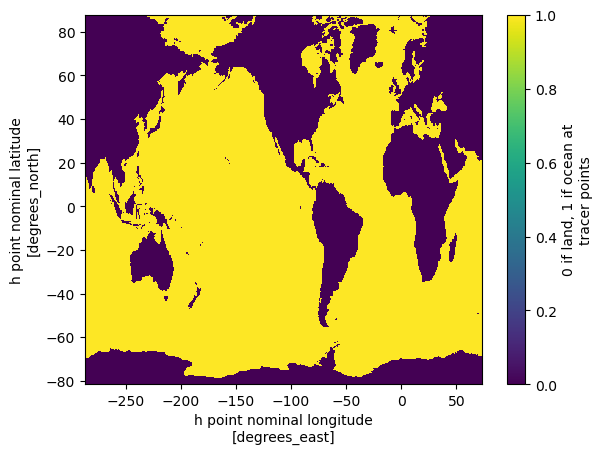

In [20]:
ds_grid.wet.plot()

### spin up dask to speed up processing

In [21]:
def get_ClusterClient():
    import dask
    from dask_jobqueue import PBSCluster
    from dask.distributed import Client
    cluster = PBSCluster(
        cores=2,
        memory='25 GB',
        processes=1,
        queue='casper',
        resource_spec='select=1:ncpus=1:mem=25GB',
        project='NCGD0011',
        walltime='03:00:00',
        interface='ext',
        log_directory='./dask-logs'
    )

    dask.config.set({
        'distributed.dashboard.link':
        'https://jupyterhub.hpc.ucar.edu/stable/user/{USER}/proxy/{port}/status'
    })
    client = Client(cluster)
    return cluster, client

In [22]:
cluster, client = get_ClusterClient()
cluster.scale(12) 
client

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/45451/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/45451/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.176:43759,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/45451/status,Total threads: 0
Started: Just now,Total memory: 0 B


### Make monthly and annual difference datasets: OAE exp - control

In [25]:
ds_diff = ds_exp - ds_ctrl

In [26]:
ds_exp_ann = ds_exp.resample({'time':'A'}).mean(dim='time').compute()

In [27]:
ds_ctrl_ann = ds_ctrl.resample({'time':'A'}).mean(dim='time').compute()

### Make a dataset that is the mean over the last 10 years

In [28]:
ds_ctrl_mean = ds_ctrl_ann.isel(time=slice(30,40)).mean(dim='time')

In [29]:
ds_exp_mean = ds_exp_ann.isel(time=slice(30,40)).mean(dim='time')

In [31]:
ds_diff_mean = ds_exp_mean - ds_ctrl_mean

## Exploratory maps

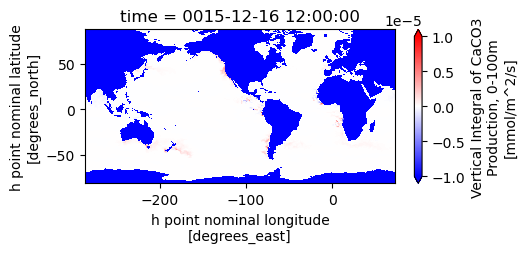

In [32]:
ds_diff.CaCO3_PROD_zint_100m.isel(time=179).where(ds_grid.wet>0,other=-999).plot(figsize=(5,2),vmin=-0.00001,vmax=0.00001, cmap='bwr')

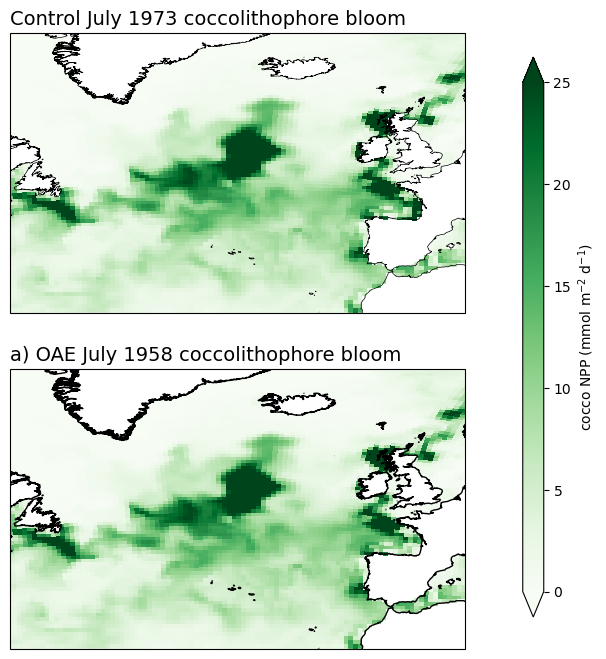

In [33]:
fig = plt.figure(figsize=(7,8))

############### 
ax = fig.add_subplot(2,1,1, projection=ccrs.PlateCarree())
ax.set_extent([-60, 5, 30, 70], ccrs.PlateCarree())

ax.set_title('Control July 1973 coccolithophore bloom', loc='left',fontsize=14)

field = ds_ctrl.photoC_cocco_zint.isel(time=174) * 86400 #mmol/m2/d

pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='Greens',
                   vmin=0,vmax=25)

ax.coastlines('10m',linewidth=0.5)

#cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='cocco NPP (mmol m$^{-2}$ d$^{-21}$)')
#############
ax = fig.add_subplot(2,1,2, projection=ccrs.PlateCarree())
ax.set_extent([-60, 5, 30, 70], ccrs.PlateCarree())
ax.set_title('a) OAE July 1958 coccolithophore bloom', loc='left',fontsize=14)

field = ds_exp.photoC_cocco_zint.isel(time=174) * 86400 #mmol/m2/d

pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='Greens',
                   vmin=0,vmax=25)

ax.coastlines('10m',linewidth=1)

############
cbar_ax = fig.add_axes([0.92, 0.15, 0.03, 0.7])
fig.colorbar(pc, cax=cbar_ax,extend='both',label='cocco NPP (mmol m$^{-2}$ d$^{-1}$)')

#fig.savefig('/glade/work/kristenk/figs/NAtl_cocco_bloom.png', bbox_inches='tight', dpi=300, format='png');

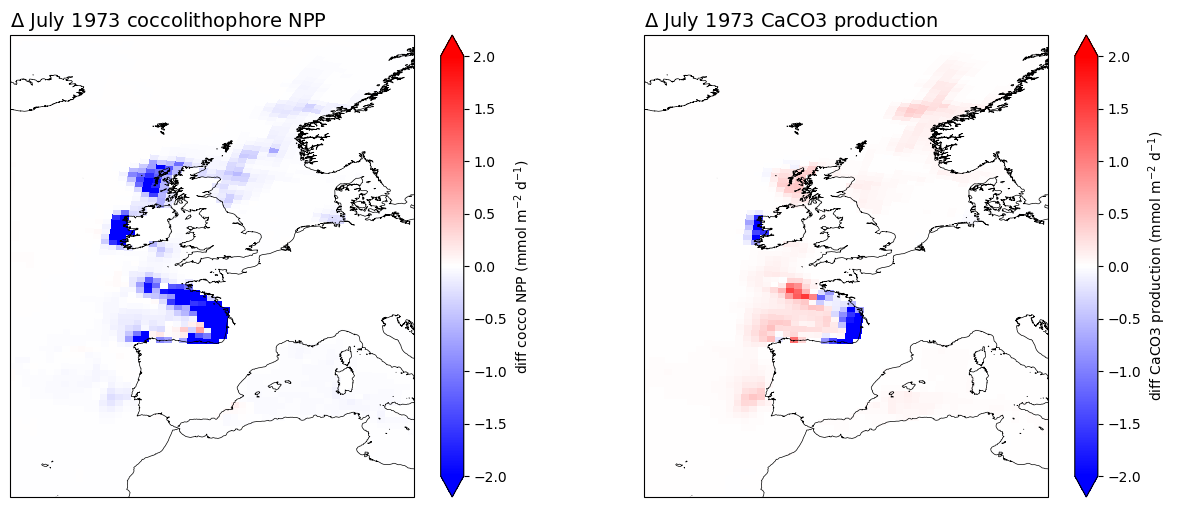

In [34]:
fig = plt.figure(figsize=(15,6))

############### 
ax = fig.add_subplot(1,2,1, projection=ccrs.PlateCarree())
ax.set_extent([-20, 15, 30, 70], ccrs.PlateCarree())

ax.set_title('${\Delta}$ July 1973 coccolithophore NPP', loc='left', fontsize=14)

field = ds_diff.photoC_cocco_zint.isel(time=174) * 86400 #mmol/m2/d

pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='bwr',
                   vmin=-2,vmax=2)

ax.coastlines('10m',linewidth=0.5)

cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='diff cocco NPP (mmol m$^{-2}$ d$^{-1}$)')

############### 
ax = fig.add_subplot(1,2,2, projection=ccrs.PlateCarree())
ax.set_extent([-20, 15, 30, 70], ccrs.PlateCarree())

ax.set_title('${\Delta}$ July 1973 CaCO3 production', loc='left', fontsize=14)

field = ds_diff.CaCO3_PROD_zint_100m.isel(time=174) * 86400 #mmol/m2/d

pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='bwr',
                   vmin=-2,vmax=2)

ax.coastlines('10m',linewidth=0.5)

cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='diff CaCO3 production (mmol m$^{-2}$ d$^{-1}$)')


#fig.savefig('/glade/work/kristenk/figs/NAtl_cocco_response.png', bbox_inches='tight', dpi=300, format='png');

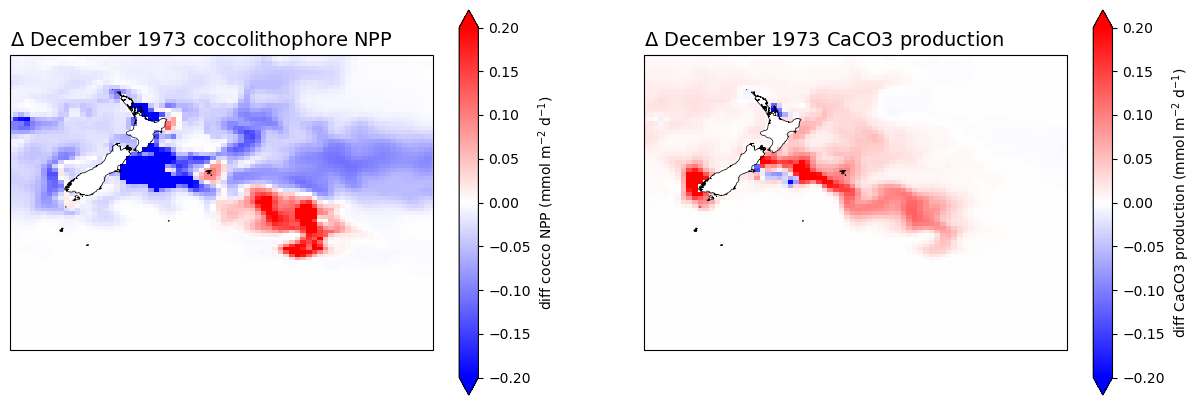

In [35]:
fig = plt.figure(figsize=(15,5))
extent = [160, 210, -65, -30]
############### 
ax = fig.add_subplot(1,2,1, projection=ccrs.PlateCarree(central_longitude=180))
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('${\Delta}$ December 1973 coccolithophore NPP', loc='left', fontsize=14)

field = ds_diff.photoC_cocco_zint.isel(time=179) * 86400 #mmol/m2/d

pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='bwr',
                   vmin=-0.2,vmax=0.2)

ax.coastlines('10m',linewidth=0.5)

cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='diff cocco NPP (mmol m$^{-2}$ d$^{-1}$)')

############### 
ax = fig.add_subplot(1,2,2, projection=ccrs.PlateCarree(central_longitude=180))
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('${\Delta}$ December 1973 CaCO3 production', loc='left', fontsize=14)

field = ds_diff.CaCO3_PROD_zint_100m.isel(time=179) * 86400 #mmol/m2/d

pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='bwr',
                   vmin=-0.2,vmax=0.2)

ax.coastlines('10m',linewidth=0.5)

cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='diff CaCO3 production (mmol m$^{-2}$ d$^{-1}$)')


#fig.savefig('/glade/work/kristenk/figs/NAtl_cocco_response.png', bbox_inches='tight', dpi=300, format='png');

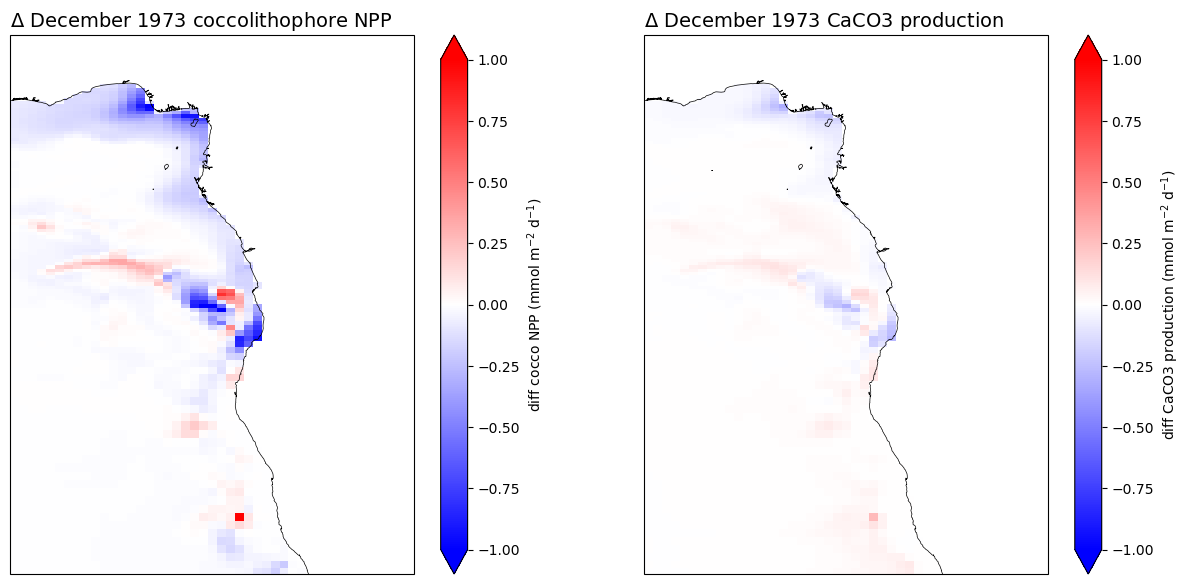

In [36]:
fig = plt.figure(figsize=(15,7))
extent = [-5, 25, -30, 10]
############### 
ax = fig.add_subplot(1,2,1, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('${\Delta}$ December 1973 coccolithophore NPP', loc='left', fontsize=14)

field = ds_diff.photoC_cocco_zint.isel(time=155) * 86400 #mmol/m2/d

pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='bwr',
                   vmin=-1,vmax=1)

ax.coastlines('10m',linewidth=0.5)

cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='diff cocco NPP (mmol m$^{-2}$ d$^{-1}$)')

############### 
ax = fig.add_subplot(1,2,2, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('${\Delta}$ December 1973 CaCO3 production', loc='left', fontsize=14)

field = ds_diff.CaCO3_PROD_zint_100m.isel(time=155) * 86400 #mmol/m2/d

pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='bwr',
                   vmin=-1,vmax=1)

ax.coastlines('10m',linewidth=0.5)

cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='diff CaCO3 production (mmol m$^{-2}$ d$^{-1}$)')


#fig.savefig('/glade/work/kristenk/figs/NAtl_cocco_response.png', bbox_inches='tight', dpi=300, format='png');

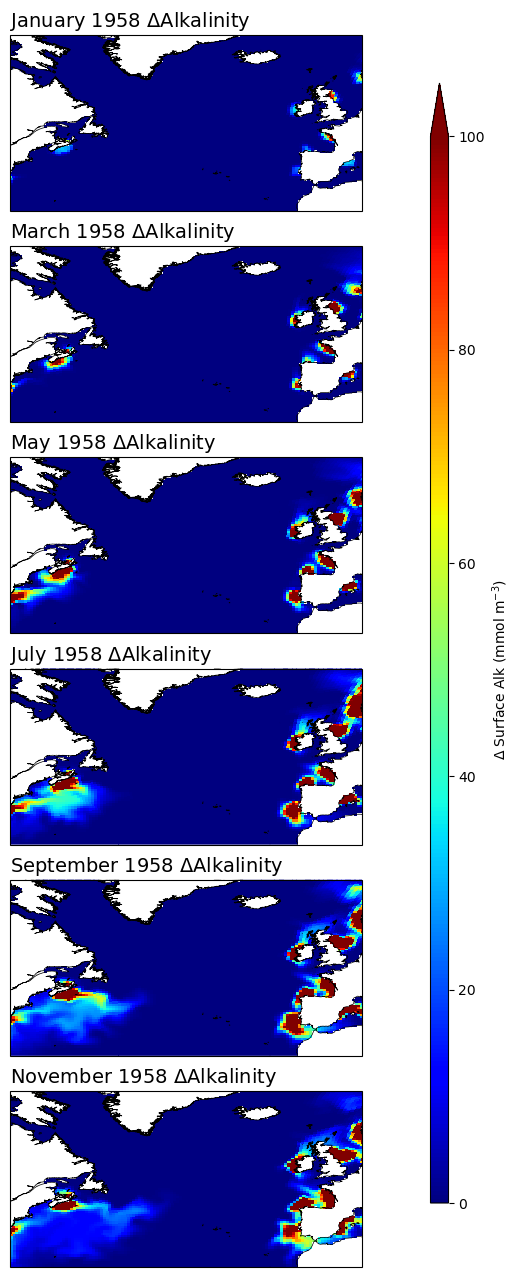

In [39]:
fig = plt.figure(figsize=(6,16))

extent=[-75, 5, 30, 70]

############### 
ax = fig.add_subplot(6,1,1, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('January 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=0,z_l=0)

pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)

ax.coastlines('10m',linewidth=0.5)

#cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='${\Delta}$ Surface Alk (mmol m$^{-3}$)')

ax = fig.add_subplot(6,1,2, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('March 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=2,z_l=0)
pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)
ax.coastlines('10m',linewidth=0.5)


###########
ax = fig.add_subplot(6,1,3, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('May 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=4,z_l=0)
pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)
ax.coastlines('10m',linewidth=0.5)

###########
ax = fig.add_subplot(6,1,4, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('July 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=6,z_l=0)
pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)
ax.coastlines('10m',linewidth=0.5)


###########
ax = fig.add_subplot(6,1,5, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('September 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=8,z_l=0)
pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)
ax.coastlines('10m',linewidth=0.5)

###########
ax = fig.add_subplot(6,1,6, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('November 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=10,z_l=0)
pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)
ax.coastlines('10m',linewidth=0.5)

cbar_ax = fig.add_axes([0.92, 0.15, 0.03, 0.7])
fig.colorbar(pc, cax=cbar_ax,extend='max',label='${\Delta}$ Surface Alk (mmol m$^{-3}$)')



#fig.savefig('/glade/work/kristenk/figs/NAtl_extra_alk_fluxes.png', bbox_inches='tight', dpi=300, format='png');

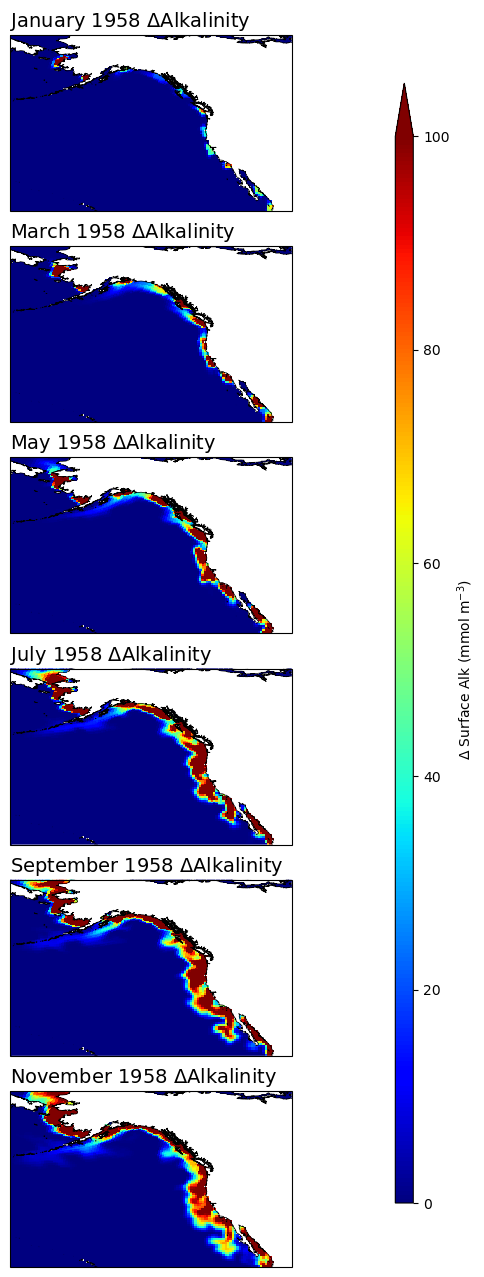

In [40]:
fig = plt.figure(figsize=(6,16))

extent=[-180, -100, 20, 70]

############### 
ax = fig.add_subplot(6,1,1, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('January 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=0,z_l=0)

pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)

ax.coastlines('10m',linewidth=0.5)

#cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='${\Delta}$ Surface Alk (mmol m$^{-3}$)')

ax = fig.add_subplot(6,1,2, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('March 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=2,z_l=0)
pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)
ax.coastlines('10m',linewidth=0.5)


###########
ax = fig.add_subplot(6,1,3, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('May 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=4,z_l=0)
pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)
ax.coastlines('10m',linewidth=0.5)

###########
ax = fig.add_subplot(6,1,4, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('July 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=6,z_l=0)
pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)
ax.coastlines('10m',linewidth=0.5)


###########
ax = fig.add_subplot(6,1,5, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('September 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=8,z_l=0)
pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)
ax.coastlines('10m',linewidth=0.5)

###########
ax = fig.add_subplot(6,1,6, projection=ccrs.PlateCarree())
ax.set_extent(extent, ccrs.PlateCarree())

ax.set_title('November 1958 ${\Delta}$Alkalinity', loc='left',fontsize=14)

field = ds_diff.ALK.isel(time=10,z_l=0)
pc = ax.pcolormesh(lons,lats,field,
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=0,vmax=100)
ax.coastlines('10m',linewidth=0.5)

cbar_ax = fig.add_axes([0.92, 0.15, 0.03, 0.7])
fig.colorbar(pc, cax=cbar_ax,extend='max',label='${\Delta}$ Surface Alk (mmol m$^{-3}$)')



#fig.savefig('/glade/work/kristenk/figs/Pac_extra_alk_fluxes.png', bbox_inches='tight', dpi=300, format='png');

### Read in OAE locations data

In [46]:
ds_reg_locs = xr.open_dataset('/glade/derecho/scratch/kristenk/OAE_experiment_data/OAEreg_coords4plotting.nc')

### Global difference maps

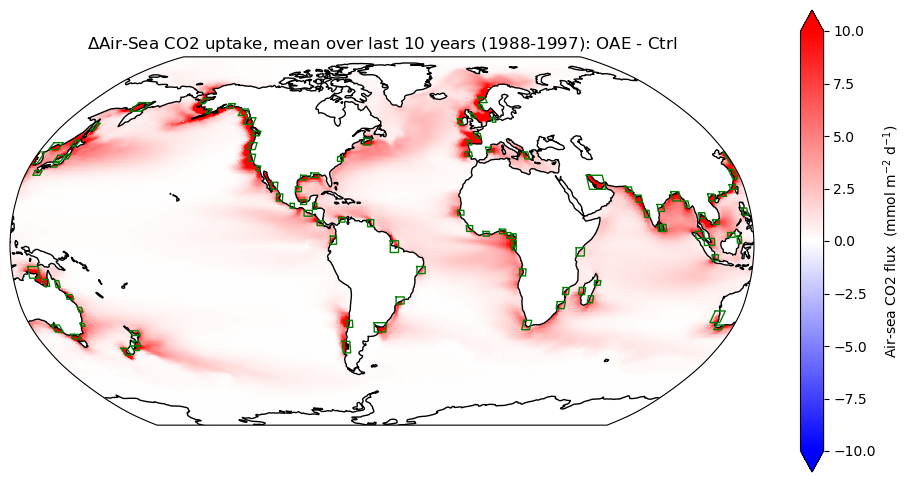

In [154]:
fig = plt.figure(figsize=(12,6))

ax = fig.add_subplot(1,1,1, projection=ccrs.Robinson(central_longitude=305.0))
ax.set_title('${\Delta}$Air-Sea CO2 uptake, mean over last 10 years (1988-1997): OAE - Ctrl', fontsize=12)
pc=ax.pcolormesh(lons, lats, ds_diff_mean.FG_CO2 * 86400, cmap='bwr',vmin=-10,vmax=10,transform=ccrs.PlateCarree())
ax.coastlines('110m',linewidth=1)

for reg in ds_reg_locs.reg_num:

    lonmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=0).values
    lonmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=1).values
    latmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=2).values
    latmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=3).values
    lon_pts = [lonmin,lonmax,lonmax,lonmin,lonmin]
    lat_pts = [latmax,latmax,latmin,latmin,latmax]
    ax.plot(lon_pts, lat_pts, color="green", linewidth=1,transform=ccrs.PlateCarree())


cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='Air-sea CO2 flux  (mmol m$^{-2}$ d$^{-1}$)')

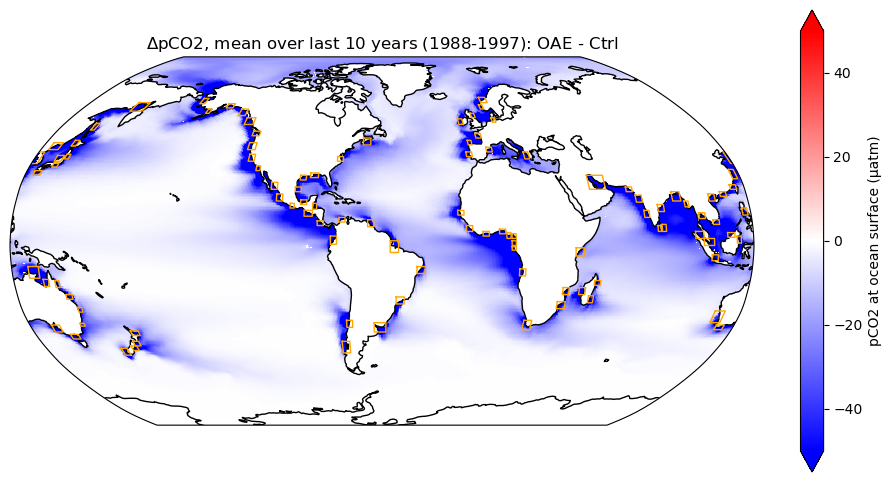

In [156]:
fig = plt.figure(figsize=(12,6))

ax = fig.add_subplot(1,1,1, projection=ccrs.Robinson(central_longitude=305.0))
ax.set_title('${\Delta}$pCO2, mean over last 10 years (1988-1997): OAE - Ctrl', fontsize=12)
pc=ax.pcolormesh(lons, lats, ds_diff_mean.pCO2SURF, cmap='bwr',
                 vmin=-50,vmax=50,
                 transform=ccrs.PlateCarree())
ax.coastlines('110m',linewidth=1)

for reg in ds_reg_locs.reg_num:

    lonmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=0).values
    lonmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=1).values
    latmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=2).values
    latmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=3).values
    lon_pts = [lonmin,lonmax,lonmax,lonmin,lonmin]
    lat_pts = [latmax,latmax,latmin,latmin,latmax]
    ax.plot(lon_pts, lat_pts, color="orange", linewidth=1,transform=ccrs.PlateCarree())


cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='pCO2 at ocean surface (µatm)')

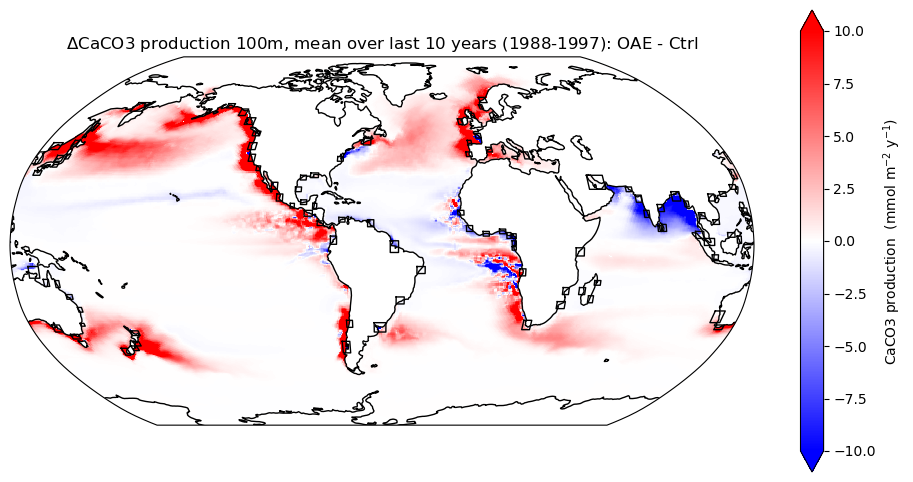

In [157]:
fig = plt.figure(figsize=(12,6))

ax = fig.add_subplot(1,1,1, projection=ccrs.Robinson(central_longitude=305.0))
ax.set_title('${\Delta}$CaCO3 production 100m, mean over last 10 years (1988-1997): OAE - Ctrl', fontsize=12)
pc=ax.pcolormesh(lons, lats, ds_diff_mean.CaCO3_PROD_zint_100m * 86400 * 365, cmap='bwr',
                 vmin=-10,vmax=10,
                 transform=ccrs.PlateCarree())
ax.coastlines('110m',linewidth=1)

for reg in ds_reg_locs.reg_num:

    lonmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=0).values
    lonmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=1).values
    latmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=2).values
    latmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=3).values
    lon_pts = [lonmin,lonmax,lonmax,lonmin,lonmin]
    lat_pts = [latmax,latmax,latmin,latmin,latmax]
    ax.plot(lon_pts, lat_pts, color="black", linewidth=1,transform=ccrs.PlateCarree())


cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='CaCO3 production  (mmol m$^{-2}$ y$^{-1}$)')

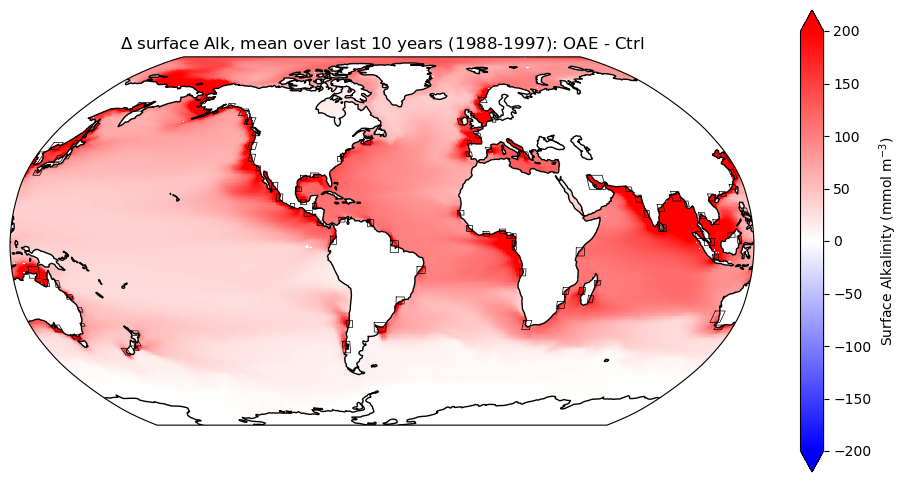

In [71]:
fig = plt.figure(figsize=(12,6))

ax = fig.add_subplot(1,1,1, projection=ccrs.Robinson(central_longitude=305.0))
ax.set_title('${\Delta}$ surface Alk, mean over last 10 years (1988-1997): OAE - Ctrl', fontsize=12)
pc=ax.pcolormesh(lons, lats, ds_diff_mean.ALK.isel(z_l=0), cmap='bwr',
                 vmin=-200,vmax=200,
                 transform=ccrs.PlateCarree())
ax.coastlines('110m',linewidth=1)

for reg in ds_reg_locs.reg_num:

    lonmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=0).values
    lonmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=1).values
    latmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=2).values
    latmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=3).values
    lon_pts = [lonmin,lonmax,lonmax,lonmin,lonmin]
    lat_pts = [latmax,latmax,latmin,latmin,latmax]
    ax.plot(lon_pts, lat_pts, color="black", linewidth=0.5,transform=ccrs.PlateCarree())


cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='Surface Alkalinity (mmol m$^{-3}$)')

### Global carbon cycle fluxes

In [74]:
ds_glb_ctrl = xr.Dataset()
ds_glb_exp = xr.Dataset()
mmols_to_PgCyr = 1e-3 * 12. * 1e-15 * 365. * 86400.

variables = [f'photoC_{phyto}_zint' for phyto in ['diat', 'sp', 'diaz', 'cocco', 'TOT']]
variables = variables + ['CaCO3_PROD_zint_100m','POC_FLUX_100m','FG_CO2']

for v in variables:
    ds_glb_ctrl[v] = ((ds_ctrl[v] * area).sum(dim=('xh', 'yh'))).compute() #mmol/m
    ds_glb_ctrl[v].attrs = ds_ctrl[v].attrs
    ds_glb_ctrl[v] = ds_glb_ctrl[v] * mmols_to_PgCyr        
    ds_glb_ctrl[v].attrs['units'] = 'Pg C yr$^{-1}$'


    ds_glb_exp[v] = ((ds_exp[v] * area).sum(dim=('xh', 'yh'))).compute() #mmol/m
    ds_glb_exp[v].attrs = ds_exp[v].attrs
    ds_glb_exp[v] = ds_glb_exp[v] * mmols_to_PgCyr        
    ds_glb_exp[v].attrs['units'] = 'Pg C yr$^{-1}$'

    
ds_glb_ctrl_ann = ds_glb_ctrl.resample({'time':'A'}).mean(dim='time').compute()
ds_glb_exp_ann = ds_glb_exp.resample({'time':'A'}).mean(dim='time').compute()

### Line plots of global sums

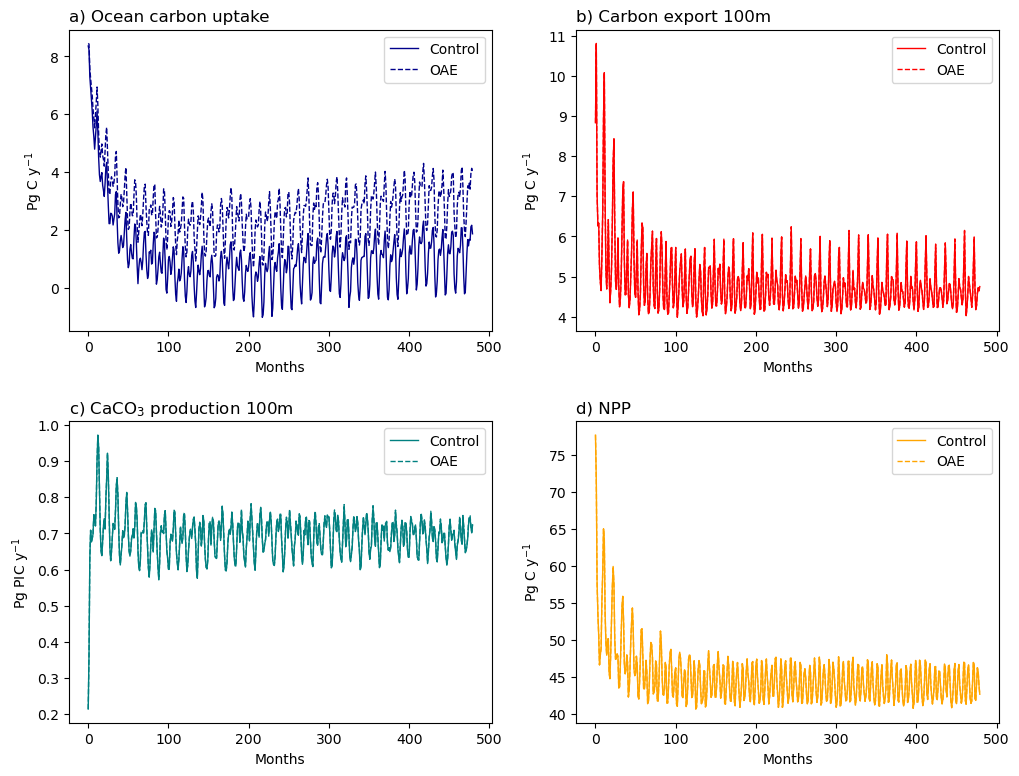

In [77]:
fig = plt.figure(figsize=(12,9))

#############################
ax = fig.add_subplot(2, 2, 1)
ax.set_title("a) Ocean carbon uptake", loc="left", fontsize=12)
   
ax.plot(ds_glb_ctrl['FG_CO2'],
           color='darkblue', zorder=2, linewidth=1, label='Control')
   
ax.plot(ds_glb_exp['FG_CO2'],
           color='darkblue', zorder=2, linewidth=1,linestyle='--',label='OAE')

ax.set_ylabel('Pg C y$^{-1}$') #, labelpad=-1)
ax.set_xlabel('Months') #, labelpad=-1)
ax.legend()

#############################
ax = fig.add_subplot(2, 2, 2)
ax.set_title("b) Carbon export 100m", loc="left", fontsize=12)
    
ax.plot(ds_glb_ctrl['POC_FLUX_100m'],
           color='red', zorder=2, linewidth=1, label='Control')
 
ax.plot(ds_glb_exp['POC_FLUX_100m'],
           color='red', zorder=2, linewidth=1,linestyle='--',label='OAE')

ax.set_ylabel('Pg C y$^{-1}$') #, labelpad=-1)
ax.set_xlabel('Months') #, labelpad=-1)
ax.legend()

#############################
ax = fig.add_subplot(2, 2, 3)
ax.set_title("c) CaCO$_3$ production 100m", loc="left", fontsize=12)
    
ax.plot(ds_glb_ctrl['CaCO3_PROD_zint_100m'],
           color='teal', zorder=2, linewidth=1, label='Control')

ax.plot(ds_glb_exp['CaCO3_PROD_zint_100m'],
           color='teal', zorder=2, linewidth=1,linestyle='--',label='OAE')

ax.set_ylabel('Pg PIC y$^{-1}$') #, labelpad=-1)
ax.set_xlabel('Months') #, labelpad=-1)
ax.legend()

#############################
ax = fig.add_subplot(2, 2, 4)
ax.set_title("d) NPP", loc="left", fontsize=12)


ax.plot(ds_glb_ctrl['photoC_TOT_zint'],
           color='orange', zorder=2, linewidth=1, label='Control')
    
ax.plot(ds_glb_exp['photoC_TOT_zint'],
           color='orange', zorder=2, linewidth=1,linestyle='--',label='OAE')

ax.legend()
ax.set_xlabel('Months') #, labelpad=-1)
ax.set_ylabel('Pg C y$^{-1}$') #, labelpad=-1)

fig.subplots_adjust(hspace=0.3)
#fig.savefig('/glade/work/kristenk/figs/Global_line_plots_OAEvControl.png', bbox_inches='tight', dpi=300, format='png');

### Plot annual means

In [78]:
ds_glb_ctrl_ann['time'] = np.arange(1,len(ds_glb_ctrl_ann.time)+1,1)
ds_glb_exp_ann['time'] = np.arange(1,len(ds_glb_exp_ann.time)+1,1)

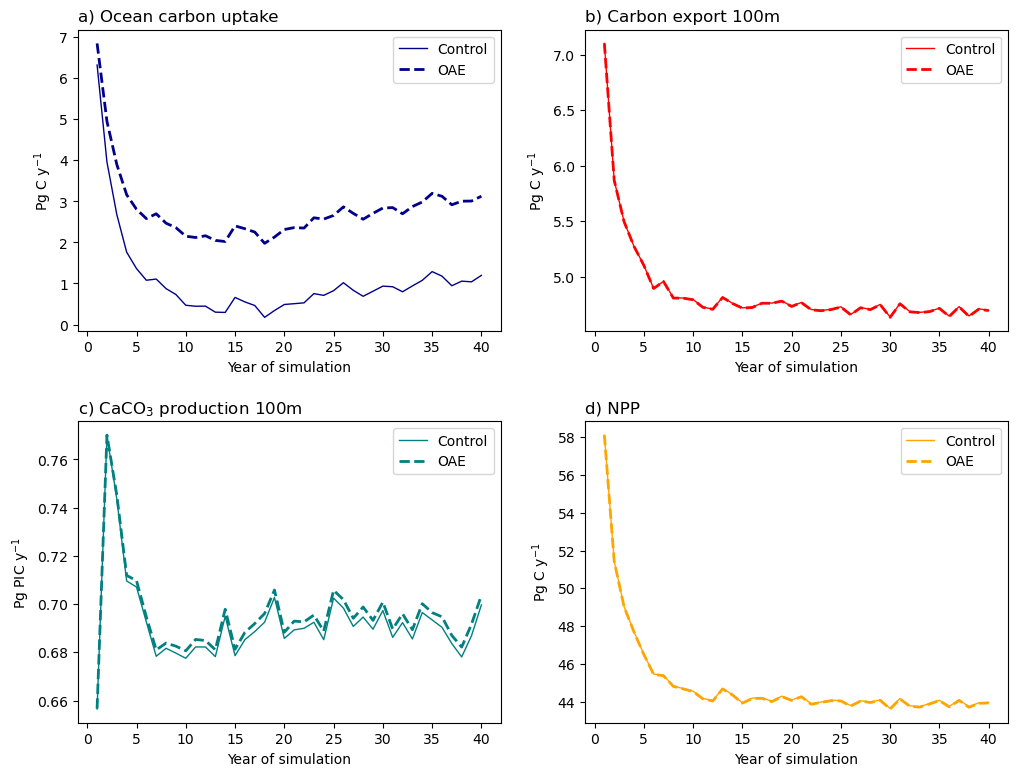

In [80]:
fig = plt.figure(figsize=(12,9))

#############################
ax = fig.add_subplot(2, 2, 1)
ax.set_title("a) Ocean carbon uptake", loc="left", fontsize=12)
   
ax.plot(ds_glb_ctrl_ann.time, ds_glb_ctrl_ann['FG_CO2'],
           color='darkblue', zorder=2, linewidth=1, label='Control')
   
ax.plot(ds_glb_exp_ann.time, ds_glb_exp_ann['FG_CO2'],
           color='darkblue', zorder=2, linewidth=2,linestyle='--',label='OAE')

ax.set_ylabel('Pg C y$^{-1}$') #, labelpad=-1)
ax.set_xlabel('Year of simulation')
ax.legend()

#############################
ax = fig.add_subplot(2, 2, 2)
ax.set_title("b) Carbon export 100m", loc="left", fontsize=12)
    
ax.plot(ds_glb_ctrl_ann.time, ds_glb_ctrl_ann['POC_FLUX_100m'],
           color='red', zorder=2, linewidth=1, label='Control')
 
ax.plot(ds_glb_exp_ann.time, ds_glb_exp_ann['POC_FLUX_100m'],
           color='red', zorder=2, linewidth=2,linestyle='--',label='OAE')

ax.set_ylabel('Pg C y$^{-1}$') #, labelpad=-1)
ax.set_xlabel('Year of simulation')
ax.legend()

#############################
ax = fig.add_subplot(2, 2, 3)
ax.set_title("c) CaCO$_3$ production 100m", loc="left", fontsize=12)
    
ax.plot(ds_glb_ctrl_ann.time, ds_glb_ctrl_ann['CaCO3_PROD_zint_100m'],
           color='teal', zorder=2, linewidth=1, label='Control')

ax.plot(ds_glb_exp_ann.time, ds_glb_exp_ann['CaCO3_PROD_zint_100m'],
           color='teal', zorder=2, linewidth=2,linestyle='--',label='OAE')

ax.set_ylabel('Pg PIC y$^{-1}$') #, labelpad=-1)
ax.set_xlabel('Year of simulation')
ax.legend()

#############################
ax = fig.add_subplot(2, 2, 4)
ax.set_title("d) NPP", loc="left", fontsize=12)


ax.plot(ds_glb_ctrl_ann.time, ds_glb_ctrl_ann['photoC_TOT_zint'],
           color='orange', zorder=2, linewidth=1, label='Control')
    
ax.plot(ds_glb_exp_ann.time, ds_glb_exp_ann['photoC_TOT_zint'],
           color='orange', zorder=2, linewidth=2,linestyle='--',label='OAE')

ax.legend()
ax.set_xlabel('Year of simulation')
ax.set_ylabel('Pg C y$^{-1}$') #, labelpad=-1)

fig.subplots_adjust(hspace=0.3)


#fig.savefig('/glade/work/kristenk/figs/Global_line_plots_OAEvControl.png', bbox_inches='tight', dpi=300, format='png');

### Plot anomalies

In [81]:
ds_glb_anom = ds_glb_exp - ds_glb_ctrl

In [82]:
deciyears = np.zeros((len(ds_glb_anom.time)),dtype=float)
nyear = (len(ds_glb_anom.time))/12
i = 0
for yr in np.arange(0,nyear,1):
    for mon in np.arange(1,13,1):
        deciyears[i] = 1958 + yr + mon/12 - 1/24
        i = i + 1
deciyears = xr.DataArray(deciyears,dims=('time'))

ds_glb_anom['time'] = deciyears

In [84]:
ds_glb_anom_ann = ds_glb_exp_ann - ds_glb_ctrl_ann
ds_glb_anom_ann['time'] = np.arange(1958.5,1998,1)

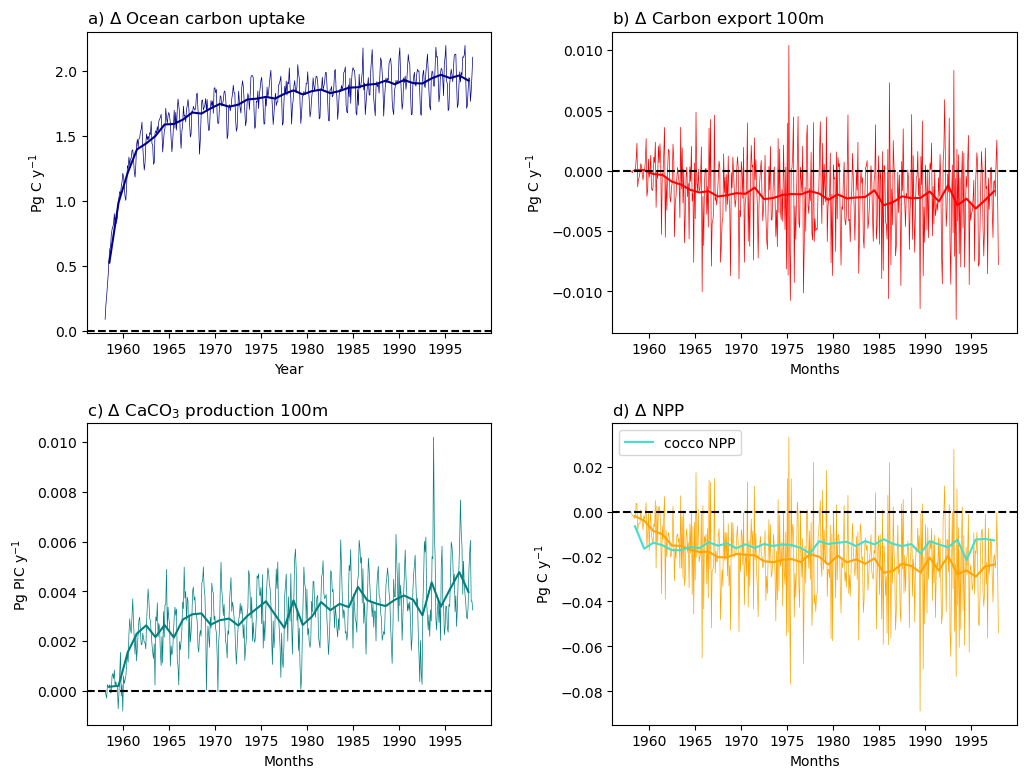

In [89]:
fig = plt.figure(figsize=(12,9))

#############################
ax = fig.add_subplot(2, 2, 1)
ax.set_title("a) ${\Delta}$ Ocean carbon uptake", loc="left", fontsize=12)
   
ax.plot(ds_glb_anom['time'],ds_glb_anom['FG_CO2'],
           color='darkblue', zorder=2, linewidth=0.5)

ax.plot(ds_glb_anom_ann['time'],ds_glb_anom_ann['FG_CO2'],
           color='darkblue', zorder=2, linewidth=1.5)


ax.axhline(0,linestyle='--',color='black')
ax.set_ylabel('Pg C y$^{-1}$') #, labelpad=-1)
ax.set_xlabel('Year') #, labelpad=-1)

#############################
ax = fig.add_subplot(2, 2, 2)
ax.set_title("b) ${\Delta}$ Carbon export 100m", loc="left", fontsize=12)
    
ax.plot(ds_glb_anom['time'], ds_glb_anom['POC_FLUX_100m'],
           color='red', zorder=2, linewidth=0.5)

ax.plot(ds_glb_anom_ann['time'], ds_glb_anom_ann['POC_FLUX_100m'],
           color='red', zorder=2, linewidth=1.5)

ax.axhline(0,linestyle='--',color='black')
ax.set_ylabel('Pg C y$^{-1}$') #, labelpad=-1)
ax.set_xlabel('Months') #, labelpad=-1)

#############################
ax = fig.add_subplot(2, 2, 3)
ax.set_title("c) ${\Delta}$ CaCO$_3$ production 100m", loc="left", fontsize=12)
    
ax.plot(ds_glb_anom['time'], ds_glb_anom['CaCO3_PROD_zint_100m'],
           color='teal', zorder=2, linewidth=0.5)
ax.plot(ds_glb_anom_ann['time'], ds_glb_anom_ann['CaCO3_PROD_zint_100m'],
           color='teal', zorder=2, linewidth=1.5)
ax.axhline(0,linestyle='--',color='black')
ax.set_ylabel('Pg PIC y$^{-1}$') #, labelpad=-1)
ax.set_xlabel('Months') #, labelpad=-1)

#############################
ax = fig.add_subplot(2, 2, 4)
ax.set_title("d) ${\Delta}$ NPP", loc="left", fontsize=12)

ax.plot(ds_glb_anom['time'], ds_glb_anom['photoC_TOT_zint'],
           color='orange', zorder=2, linewidth=0.5)

ax.plot(ds_glb_anom_ann['time'], ds_glb_anom_ann['photoC_TOT_zint'],
           color='orange', zorder=2, linewidth=1.5)

ax.plot(ds_glb_anom_ann['time'], ds_glb_anom_ann['photoC_cocco_zint'],
           color='turquoise', zorder=2, linewidth=1.5, label='cocco NPP')
ax.legend()
ax.axhline(0,linestyle='--',color='black')
ax.set_ylabel('Pg C y$^{-1}$') #, labelpad=-1)
ax.set_xlabel('Months') #, labelpad=-1)


fig.subplots_adjust(hspace=0.3, wspace=0.3)
#fig.savefig('/glade/work/kristenk/figs/Global_line_plots_OAEvControl.png', bbox_inches='tight', dpi=300, format='png');

## Where are the OAE responses for coccolithophore NPP and CaCO3 production positively and negatively correlated?

In [91]:
### first slice off the first 5 years

coccoNPPanom = ds_diff.photoC_cocco_zint.isel(time=slice(60,480))
CaCO3prodanom = ds_diff.CaCO3_PROD_zint_100m.isel(time=slice(60,480))

coccoNPP_CaCO3_prod_corr = xr.corr(coccoNPPanom,CaCO3prodanom, dim='time')
coccoNPP_CaCO3_prod_corr = coccoNPP_CaCO3_prod_corr.load()

Red areas = places where CaCO3 prod varies with coccoNPP (Indian ocean = they both drop)

Blue areas = places where coccoNPP drops due to C limitation, but CaCO3 goes up to increased PIC/POC

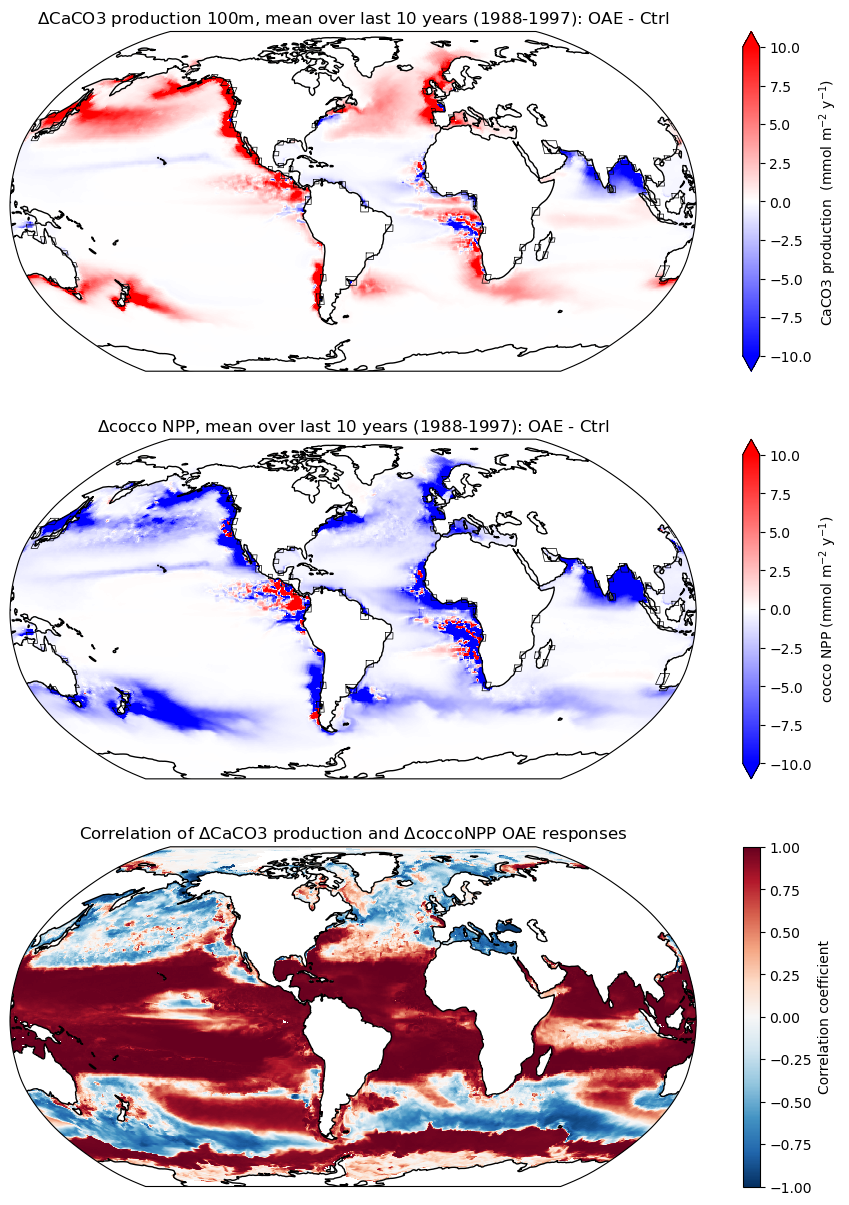

In [96]:
fig = plt.figure(figsize=(12,15))

ax = fig.add_subplot(3,1,1, projection=ccrs.Robinson(central_longitude=305.0))
ax.set_title('${\Delta}$CaCO3 production 100m, mean over last 10 years (1988-1997): OAE - Ctrl', fontsize=12)
pc=ax.pcolormesh(lons, lats, ds_diff_mean.CaCO3_PROD_zint_100m * 86400 * 365, cmap='bwr',
                 vmin=-10,vmax=10,
                 transform=ccrs.PlateCarree())
ax.coastlines('110m',linewidth=1)
for reg in ds_reg_locs.reg_num:
    lonmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=0).values
    lonmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=1).values
    latmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=2).values
    latmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=3).values
    lon_pts = [lonmin,lonmax,lonmax,lonmin,lonmin]
    lat_pts = [latmax,latmax,latmin,latmin,latmax]
    ax.plot(lon_pts, lat_pts, color="black", linewidth=0.5,transform=ccrs.PlateCarree())
cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='CaCO3 production  (mmol m$^{-2}$ y$^{-1}$)')


ax = fig.add_subplot(3,1,2, projection=ccrs.Robinson(central_longitude=305.0))
ax.set_title('${\Delta}$cocco NPP, mean over last 10 years (1988-1997): OAE - Ctrl', fontsize=12)
pc=ax.pcolormesh(lons, lats, ds_diff_mean.photoC_cocco_zint * 86400 * 365, cmap='bwr',
                 vmin=-10,vmax=10,
                 transform=ccrs.PlateCarree())
ax.coastlines('110m',linewidth=1)
for reg in ds_reg_locs.reg_num:
    lonmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=0).values
    lonmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=1).values
    latmin = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=2).values
    latmax = ds_reg_locs.OAE_regions.sel(reg_num=reg).isel(minlon_maxlon_minlat_maxlat=3).values
    lon_pts = [lonmin,lonmax,lonmax,lonmin,lonmin]
    lat_pts = [latmax,latmax,latmin,latmin,latmax]
    ax.plot(lon_pts, lat_pts, color="black", linewidth=0.5,transform=ccrs.PlateCarree())
cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='cocco NPP (mmol m$^{-2}$ y$^{-1}$)')




ax = fig.add_subplot(3,1,3, projection=ccrs.Robinson(central_longitude=305.0))
ax.set_title('Correlation of ${\Delta}$CaCO3 production and ${\Delta}$coccoNPP OAE responses', fontsize=12)
pc=ax.pcolormesh(lons, lats, coccoNPP_CaCO3_prod_corr, cmap='RdBu_r',vmin=-1,vmax=1,transform=ccrs.PlateCarree())
ax.coastlines('110m',linewidth=1)
cbar1 = fig.colorbar(pc, ax=ax,label='Correlation coefficient')

### slices of Alk through depth

In [108]:
xlen = len(ds_ctrl_mean.xh)
ylen = len(ds_ctrl_mean.yh)
zlen = len(ds_ctrl_mean.z_l)

In [127]:
import importlib
importlib.reload(utils)  # Forces a re-import utils

<module 'utils' from '/glade/u/home/kristenk/Alk_NOPP_mCDR/utils.py'>

In [128]:
lons_norm = utils.normal_lons(lons)

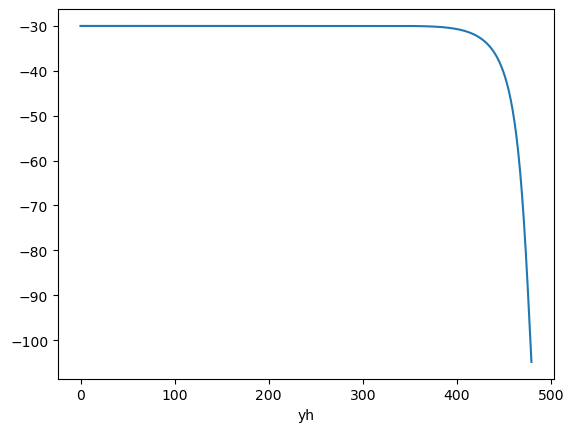

In [147]:
lons_norm.isel(xh=385).plot()

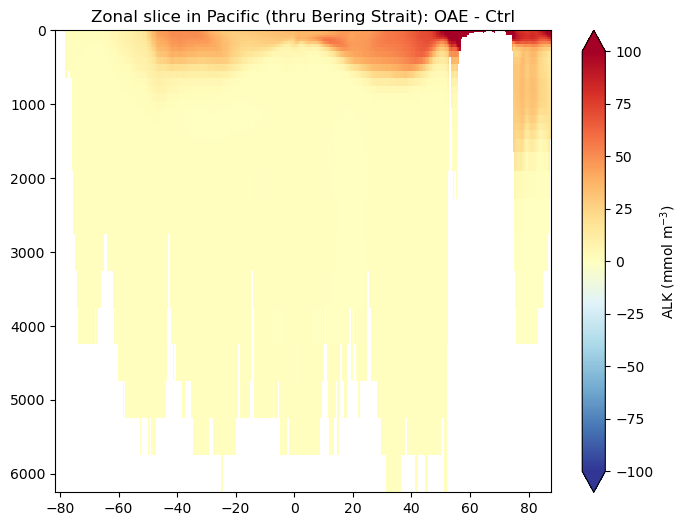

In [142]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(1,1,1)
ax.set_title('Zonal slice in Pacific (thru Bering Strait): OAE - Ctrl', fontsize=12)
pc=ax.pcolormesh(ds_diff_mean.yh, ds_diff_mean.z_l, ds_diff_mean.ALK.isel(xh=175), cmap='RdYlBu_r',
                 vmin=-100,vmax=100)
ax.invert_yaxis()
cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='ALK (mmol m$^{-3}$)')


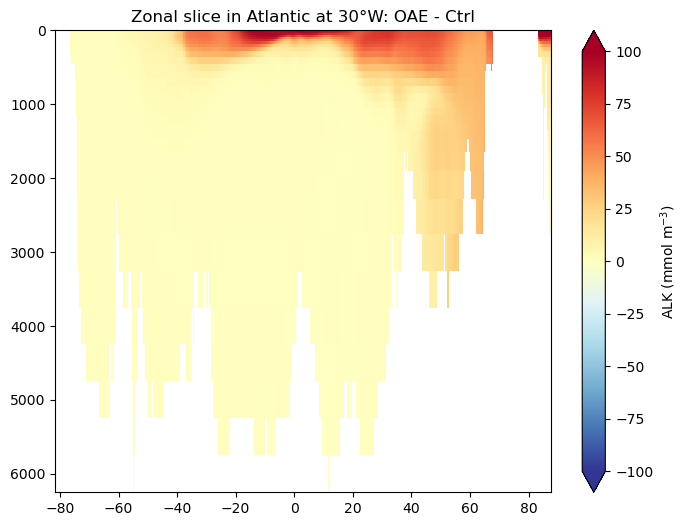

In [148]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(1,1,1)
ax.set_title('Zonal slice in Atlantic at 30°W: OAE - Ctrl', fontsize=12)
pc=ax.pcolormesh(ds_diff_mean.yh, ds_diff_mean.z_l, ds_diff_mean.ALK.isel(xh=385), cmap='RdYlBu_r',
                 vmin=-100,vmax=100)
ax.invert_yaxis()
cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='ALK (mmol m$^{-3}$)')


### Zonal mean

In [106]:
import xesmf

In [107]:
def zonal_mean(ds_in, varname, ds_grid):

    grid_in = ds_grid2.rename({'geolon': 'lon','geolat': 'lat', 'geolonb': 'lon_b',
                            'geolatb': 'lat_b', 'lath' : 'yh', 'lonh' : 'xh',
                            'latq' : 'yq', 'lonq' : 'xq'})

    lon = np.arange(0.5, 360, 1)
    lat = np.arange(-89.5, 90, 1)
    
    ds_out = xr.Dataset({"lon": (["lon"], lon),"lat": (["lat"], lat)})

    ds_in = ds_in.assign_coords(lat=grid_in.lat, lat_b=grid_in.lat_b, lon=grid_in.lon, lon_b=grid_in.lon_b)
    
    def regrid_tracer(varname, ds_in, ds_out, method='bilinear'):
    
        regrid = xesmf.Regridder(
            ds_in,
            ds_out,
            method=method,
            periodic=True,
        )
        fld_out = regrid(ds_in[varname])
        return fld_out

    var_1x1 = regrid_tracer(varname, ds_in, ds_out)

    za = var_1x1.mean(dim='lon')

    return(za)

In [110]:
ds_zonal_ctrl = xr.Dataset()

var_array = np.zeros([180, zlen])

for var in ['ALK']:
    
    for z in np.arange(0,zlen):
        
        var_array[:,z] = zonal_mean(ds_ctrl_mean.isel(z_l=z), var, ds_grid)

    ds_zonal_ctrl[var] = xr.DataArray(var_array, dims=('yh','z_l'))

In [150]:
ds_zonal_exp = xr.Dataset()

var_array = np.zeros([180, zlen])

for var in ['ALK']:
    
    for z in np.arange(0,zlen):
        
        var_array[:,z] = zonal_mean(ds_exp_mean.isel(z_l=z), var, ds_grid)

    ds_zonal_exp[var] = xr.DataArray(var_array, dims=('yh','z_l'))

### is this pattern consistent with delta CO2 (aq)??

### Look at calcToSed - does this change?

### Look at zsatarag, co3_sat_arag

## Effects on calcifiers beyond what's represetnted in the model, like west coast oysters or coral or pteropods

### what if we turn off the OAE after ~10 years?